# Phase 2 — exploratory claim clustering
This notebook starts the Phase 2 plan from the 4 September Phase 1 update.
**Scope:** ex-post segmentation of the standard SPLICE Complexity 5 portfolio.
Ultimate cost, final settlement delay and final payment count contain future
information. These groups are not a deployable reserving model.

We compare Ward hierarchical clustering and K-means for k=2–8, inspect raw-unit
profiles, and investigate feature and sampling sensitivity. No cluster count
is automatically accepted as an actuarially credible reserving segmentation.
The `_cov` portfolio and transaction-history features are deferred.
Run from the repository root or its notebooks folder.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import scipy, sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'reports' / 'phase_2'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
FEATURES = ['claim_size', 'notidel', 'setldel', 'no_payment']
claims = pd.read_csv(ROOT / 'data/raw/splice/complexity_5/claim_5.csv')
raw = claims[FEATURES].copy()
assert len(claims) == 3663 and claims.claim_no.is_unique
assert np.isfinite(raw.to_numpy()).all() and (raw >= 0).all().all()
assert (raw.no_payment % 1 == 0).all()
X = StandardScaler().fit_transform(np.log1p(raw))
assert np.allclose(X.mean(axis=0), 0, atol=1e-10)
assert np.allclose(X.std(axis=0), 1)
print(f'Validated {len(claims):,} unique claims; four finite nonnegative features.')
print({'numpy': np.__version__, 'pandas': pd.__version__,
       'scipy': scipy.__version__, 'sklearn': sklearn.__version__})


Validated 3,663 unique claims; four finite nonnegative features.
{'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1'}


## 1. Hierarchical structure
Use Ward linkage with Euclidean distance on log(1+x), standardised features.
Ward favours compact groups too: it does not solve arbitrary cluster geometry.
The truncated dendrogram summarises the last 20 branches; leaf labels are
observation indices or subtree counts, not claim identifiers.

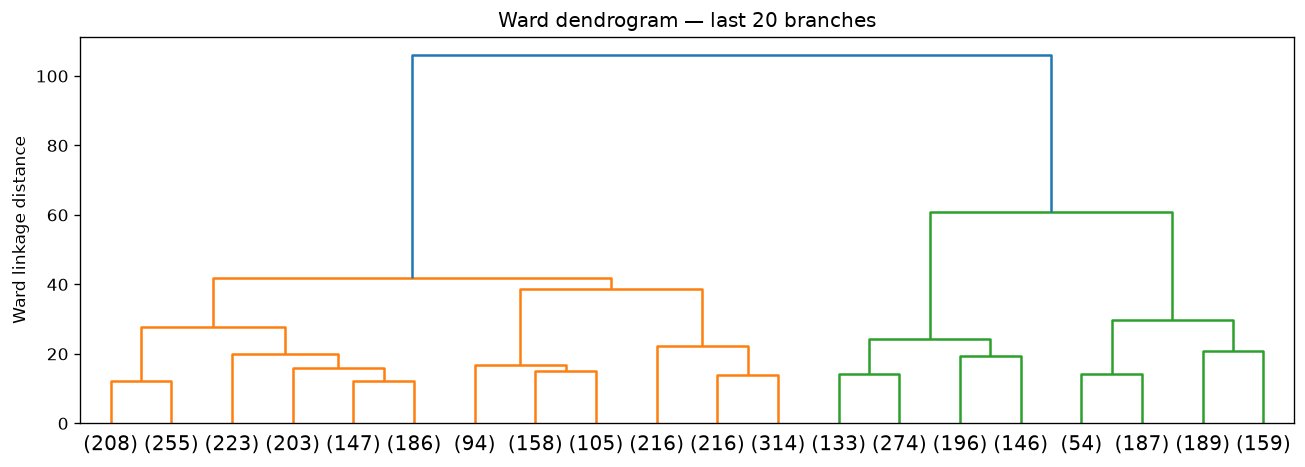

In [2]:
Z = linkage(X, method='ward', metric='euclidean')
fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Z, truncate_mode='lastp', p=20, ax=ax)
ax.set(title='Ward dendrogram — last 20 branches', ylabel='Ward linkage distance')
fig.tight_layout()
fig.savefig(OUT / 'dendrogram.png', dpi=160)
plt.show()


## 2. Compare candidate partitions
Silhouette and Calinski–Harabasz: higher is better; Davies–Bouldin: lower is
better. These describe geometry, not reserve accuracy. Silhouette uses the same
fixed sample of up to 1,500 claims for each solution; other metrics use all claims.
Minimum cluster size is shown to flag small groups. The highest Ward silhouette
is used only as a **working candidate**, pending interpretation and stability.


method  k  silhouette  davies_bouldin  calinski_harabasz  min_cluster_n  min_cluster_pct
  ward  2       0.346           1.172           2271.714           1338           36.527
kmeans  2       0.406           1.000           2563.499            932           25.444
  ward  3       0.256           1.199           1894.761            589           16.080
kmeans  3       0.257           1.285           2128.099            658           17.963
  ward  4       0.188           1.546           1608.874            589           16.080
kmeans  4       0.249           1.193           1910.646            581           15.861
  ward  5       0.196           1.349           1489.697            357            9.746
kmeans  5       0.248           1.251           1747.564            523           14.278
  ward  6       0.185           1.377           1357.017            241            6.579
kmeans  6       0.237           1.167           1659.442            440           12.012
  ward  7       0.164

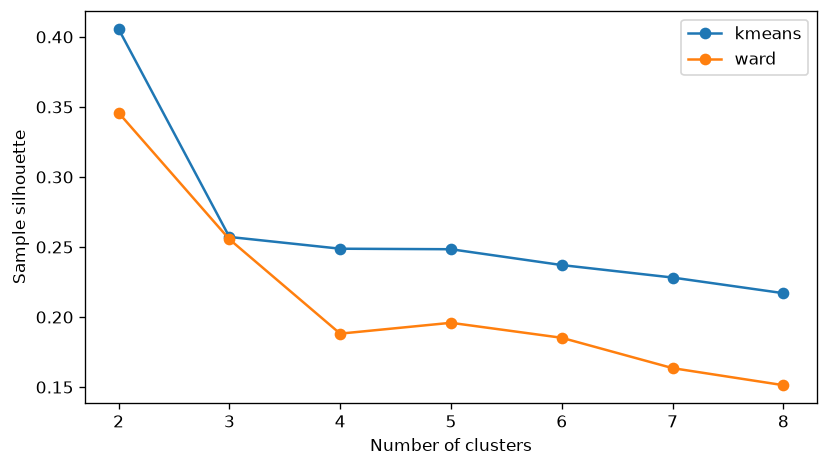

In [3]:
rows, partitions = [], {}
for k in range(2, 9):
    for method in ['ward', 'kmeans']:
        labels = (cut_tree(Z, n_clusters=k).ravel() if method == 'ward' else
                  KMeans(n_clusters=k, random_state=SEED, n_init=30).fit_predict(X))
        partitions[method, k] = labels
        sizes = np.bincount(labels)
        rows.append(dict(method=method, k=k,
            silhouette=silhouette_score(X, labels, sample_size=1500, random_state=SEED),
            davies_bouldin=davies_bouldin_score(X, labels),
            calinski_harabasz=calinski_harabasz_score(X, labels),
            min_cluster_n=int(sizes.min()), min_cluster_pct=100*sizes.min()/len(X)))
diagnostics = pd.DataFrame(rows)
diagnostics.to_csv(OUT / 'candidate_diagnostics.csv', index=False)
print(diagnostics.round(3).to_string(index=False))
candidate_k = int(diagnostics.query("method == 'ward'").sort_values('silhouette', ascending=False).iloc[0].k)
labels = partitions['ward', candidate_k]
print(f'Working candidate: Ward k={candidate_k}; not a final selection.')
print('Ward / K-means agreement (ARI):', round(adjusted_rand_score(labels, partitions['kmeans', candidate_k]), 3))
fig, ax = plt.subplots(figsize=(7, 4))
for method, group in diagnostics.groupby('method'):
    ax.plot(group.k, group.silhouette, 'o-', label=method)
ax.set(xlabel='Number of clusters', ylabel='Sample silhouette')
ax.legend(); fig.tight_layout()
fig.savefig(OUT / 'candidate_scores.png', dpi=160)
plt.show()


## 3. Describe the working candidate in original units
Cluster identifiers are arbitrary. Compare medians, upper quantiles, cost
shares and representation across occurrence periods before naming groups.
Volume and concentration are diagnostics only; no credibility threshold has
been agreed. Settlement-delay definitions follow Phase 1 without reinterpretation.


            n  claim_size_median  notidel_median  setldel_median  no_payment_median  claim_pct  cost_pct  claim_size_p95  occurrence_periods
cluster                                                                                                                                     
1        2325          147167.21            1.32            11.7                5.0      63.47     93.05       780947.46                  40
2        1338           13851.97            2.99             2.3                3.0      36.53      6.95       116989.77                  40
Minimum claims in any occurrence-period/cluster cell: 21


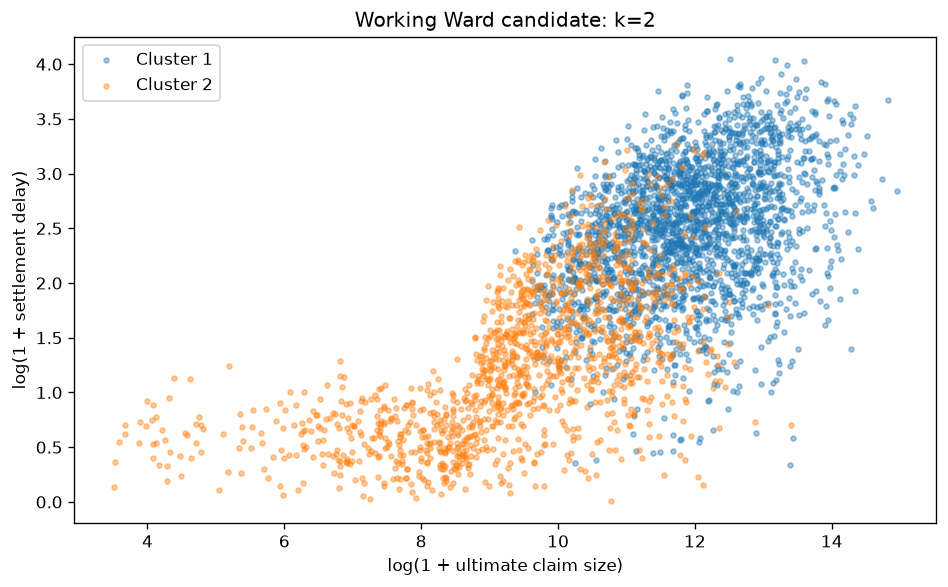

In [4]:
assigned = claims.assign(cluster=labels + 1)
g = assigned.groupby('cluster')
profile = g[FEATURES].median().add_suffix('_median')
profile.insert(0, 'n', g.size())
profile['claim_pct'] = 100*profile.n/len(claims)
profile['cost_pct'] = 100*g.claim_size.sum()/claims.claim_size.sum()
profile['claim_size_p95'] = g.claim_size.quantile(.95)
profile['occurrence_periods'] = g.occurrence_period.nunique()
profile.to_csv(OUT / 'cluster_profiles.csv')
assigned[['claim_no', 'occurrence_period', 'cluster']].to_csv(OUT / 'claim_assignments.csv', index=False)
period_counts = pd.crosstab(assigned.occurrence_period, assigned.cluster)
period_counts.to_csv(OUT / 'cluster_period_counts.csv')
print(profile.round(2).to_string())
print('Minimum claims in any occurrence-period/cluster cell:', period_counts.to_numpy().min())
fig, ax = plt.subplots(figsize=(8, 5))
for cluster, group in g:
    ax.scatter(np.log1p(group.claim_size), np.log1p(group.setldel), s=9, alpha=.4, label=f'Cluster {cluster}')
ax.set(xlabel='log(1 + ultimate claim size)', ylabel='log(1 + settlement delay)',
       title=f'Working Ward candidate: k={candidate_k}')
ax.legend(); fig.tight_layout()
fig.savefig(OUT / 'candidate_profiles.png', dpi=160)
plt.show()


## 4. Sensitivity and stability
ARI compares partitions independently of label names: 1 means agreement;
around 0 means chance-level agreement. It does not measure actuarial quality.
Compare feature subsets at the same k, refitting scaling for each subset.
Also remove the highest 1% of ultimate costs as a diagnostic (not as a proposed
data-cleaning rule), comparing labels only for the retained observations.

For sampling stability, refit Ward clustering on ten 80% subsamples and compare
with the full-sample labels restricted to the same claims. Scaling is refitted
inside each subsample. This is an initial diagnostic, not independent validation.


In [5]:
sens = []
for name, cols in {'without_payment_count': FEATURES[:-1],
                   'without_settlement_delay': ['claim_size','notidel','no_payment'],
                   'severity_reporting_only': ['claim_size','notidel']}.items():
    xs = StandardScaler().fit_transform(np.log1p(raw[cols]))
    ys = cut_tree(linkage(xs, method='ward'), n_clusters=candidate_k).ravel()
    sens.append({'experiment': name, 'n': len(xs), 'ari': adjusted_rand_score(labels, ys)})
keep = raw.claim_size <= raw.claim_size.quantile(.99)
xt = StandardScaler().fit_transform(np.log1p(raw.loc[keep]))
yt = cut_tree(linkage(xt, method='ward'), n_clusters=candidate_k).ravel()
sens.append({'experiment':'exclude_top_1pct_cost_diagnostic', 'n':len(xt),
             'ari':adjusted_rand_score(labels[keep], yt)})
sensitivity = pd.DataFrame(sens)
sensitivity.to_csv(OUT / 'feature_sensitivity.csv', index=False)
print(sensitivity.round(3).to_string(index=False))
rng = np.random.default_rng(SEED)
stability = []
for repetition in range(10):
    idx = np.sort(rng.choice(len(X), size=int(.8*len(X)), replace=False))
    xs = StandardScaler().fit_transform(np.log1p(raw.iloc[idx]))
    ys = cut_tree(linkage(xs, method='ward'), n_clusters=candidate_k).ravel()
    stability.append({'repetition':repetition+1, 'ari':adjusted_rand_score(labels[idx], ys)})
stability = pd.DataFrame(stability)
stability.to_csv(OUT / 'sampling_stability.csv', index=False)
print('Sampling stability ARI:')
print(stability.ari.describe().round(3).to_string())


                      experiment    n   ari
           without_payment_count 3663 0.583
        without_settlement_delay 3663 0.408
         severity_reporting_only 3663 0.407
exclude_top_1pct_cost_diagnostic 3626 0.432
Sampling stability ARI:
count    10.000
mean      0.365
std       0.125
min       0.222
25%       0.292
50%       0.351
75%       0.381
max       0.655


## 5. Decisions still needed with the team
1. Compare the working candidate with neighbouring k values using profiles,
   group sizes and occurrence-period counts; do not select by one metric alone.
2. Discuss whether sensitivity to correlated inputs changes the interpretation.
3. Agree what constitutes sufficient volume and development support for a
   reserving group. Large total claim counts alone do not establish credibility.
4. Investigate alternative linkage or model-based methods if geometry warrants it.
5. Define a valuation-date experiment with observable features and subsequent
   outcomes before claiming any improvement to reserving.
6. Coordinate with Nawfal before combining this initial work with his progress.

Reproduce this notebook with the project dependencies plus scipy and nbformat.
All generated tables and figures are under reports/phase_2.
